# Results and testing, for the project report

This notebook rebuilds every number the report needs from the result files in `results/` and `runs/`, with
95% confidence intervals and paired tests. It runs no simulation, so it takes seconds. A missing file is
reported and its section skipped. Section 9 lists the commands that make each file.

**Suggested report structure** (the sections below follow its results part):

1. **Introduction**: reshelving is the manual step left in the library loop (NLB figures); the task;
   the four row states (clear, tight, leaning, packed); contributions.
2. **Related work**: book insertion that assumes an open gap; residual RL; perception for shelves.
3. **System**
   - 3.1 Simulation: bookcase, real PBBM books with hinged pages, settling, the Panda with 12 cm fingers.
   - 3.2 Scripted closed-loop controller: look → stand up / widen / shove / insert, repeated.
   - 3.3 Perception: three-view RGB-D sweep, Mask R-CNN masks, spine fitting, D405 and calibration errors, fiducials.
   - 3.4 Residual PPO: observation, target-mode action and bounds, reward, asymmetric critic.
   - 3.5 Learned high-level policy: actions, features, valid-action masks, fitted Q iteration.
   - 3.6 Cart demo: the full pipeline from the tray to the shelf.
4. **Experimental setup**: test sets and what never touches them (section 1 here), metrics, perception modes.
5. **Results**: controller (2), fiducials (3), residual (4–5), high-level policy (6), cart (7).
6. **Discussion**: where books are lost (perception, reach), why the residual barely helps, limitations
   (soft covers, magic set-aside, macOS depth precision, small test sets).
7. **Conclusion and future work.**

In [1]:
import sys, json, math, pathlib, collections, statistics as st
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
SCEN = ("clear", "tight", "leaning", "packed")

def load(rel):
    p = ROOT / rel
    if not p.exists():
        print(f"(missing: {rel})")
        return None
    if p.suffix == ".jsonl":
        return [json.loads(l) for l in open(p) if l.strip()]
    return json.load(open(p))

def wilson(k, n, z=1.96):
    # 95% interval of a success rate: honest at small n and near 0% / 100%
    if n == 0:
        return (float("nan"),) * 2
    p, d = k / n, 1 + z * z / n
    c, h = (p + z * z / (2 * n)) / d, z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0, c - h), min(1, c + h)

def rate(k, n):
    lo, hi = wilson(k, n)
    return f"{k}/{n} = {100*k/n:.0f}% [{100*lo:.0f}, {100*hi:.0f}]" if n else "-"

def mcnemar(b, c):
    # exact two-sided test on the discordant pairs: b rows only A placed, c rows only B placed
    n = b + c
    if n == 0:
        return 1.0
    return min(1.0, 2 * sum(math.comb(n, i) for i in range(min(b, c) + 1)) / 2 ** n)

def paired(A, B, ok=lambda r: bool(r.get("success"))):
    keys = sorted(set(A) & set(B))
    b = [k for k in keys if ok(A[k]) and not ok(B[k])]
    c = [k for k in keys if ok(B[k]) and not ok(A[k])]
    return len(keys), b, c, mcnemar(len(b), len(c))

def by_row(rows):
    return {(r["scenario"], r["seed"]): r for r in rows} if rows else {}

## 1. The test sets, and what never touches them

A result only counts as a test if nothing was trained or tuned on its rows. Seeds pick the scene
(layout, books, friction, camera noise), so disjoint seed ranges mean disjoint scenes.

| Experiment | Trained / tuned on | Tested on |
|---|---|---|
| Segmenter | 2,938 images from random scenes (`make_vision_dataset`) | the controller's rows below |
| Controller (scripted) | hand-tuned on README rows, seeds 0–199 | seeds 0–49 (Results slide), 0–99 (fiducials) |
| Residual PPO | pools from seeds 10000+ (training and validation) | pools from 30000+ (**unfinished**) |
| High-level policy | seeds 5000–5059 | seeds 0–24 |

The controller was tuned by looking at failures on seeds 0–199, so its own numbers are not held out. They
measure the system, not a learned model, and they are the baseline the learned parts are compared with.

In [2]:
ranges = {"high-level train": range(5000, 5060), "high-level test": range(0, 25),
          "residual train/val": range(10000, 10250), "residual test": range(30000, 30120),
          "controller test": range(0, 50)}
checks = [("high-level train", "high-level test"), ("residual train/val", "residual test"),
          ("residual train/val", "controller test"), ("high-level train", "controller test")]
for a, b in checks:
    overlap = set(ranges[a]) & set(ranges[b])
    print(f"{a:20} vs {b:16}: {'OK, disjoint' if not overlap else f'OVERLAP {len(overlap)} seeds'}")

# and in the files themselves
hl_train, hl_test = load("results/hl_train.jsonl"), load("results/hl_eval_q.jsonl")
if hl_train and hl_test:
    print("high-level files share rows:", bool(set(by_row(hl_train)) & set(by_row(hl_test))))
lab, lab_test = load("results/labels.jsonl"), load("results/labels_test.jsonl")
if lab and lab_test:
    k = lambda r: (r["scenario"], r["geometry_seed"])
    print("residual label files share layouts:", bool({k(r) for r in lab} & {k(r) for r in lab_test}))

high-level train     vs high-level test : OK, disjoint
residual train/val   vs residual test   : OK, disjoint
residual train/val   vs controller test : OK, disjoint
high-level train     vs controller test : OK, disjoint
high-level files share rows: False
residual label files share layouts: False


## 2. The controller: truth against the camera (real books)

`results/slide_check/`: real PBBM books (`--catalogue`), 4 hinged page sections, covers drawn, seeds 0–49,
the learned segmenter on the camera. Rerun on this machine to check the presentation's Results slide.

- **Placed**: the book upright, in place and let go of, with 95% interval.
- **Time to seat**: median simulated seconds, on the rows that truth placed too (as on the slide).
- **Moved**: median of the most-moved neighbour (not the inserted book).

In [3]:
SLIDE = {"truth": dict(clear=50, tight=49, leaning=48, packed=42), "camera": dict(clear=47, tight=39, leaning=44, packed=24)}
cols = {f: by_row(load(f"results/slide_check/{f}.jsonl")) for f in ("truth", "camera")}
T = cols["truth"]
print(f"{'':16}{'placed (95% CI)':30}{'slide':>7}{'seat s':>8}{'moved mm':>10}")
for s in SCEN:
    for f, D in cols.items():
        rs = [r for k, r in D.items() if k[0] == s]
        if not rs:
            continue
        ok = sum(bool(r.get("success")) for r in rs)
        seat = [r["time_to_seat_s"] for k, r in D.items() if k[0] == s and r.get("success")
                and T.get(k, {}).get("success") and r.get("time_to_seat_s") is not None]
        moved = [1000 * r["neighbour_shift_m"] for r in rs if r.get("neighbour_shift_m") is not None]
        flag = "" if len(rs) == 50 else f"  ({len(rs)} of 50 rows run)"
        print(f"{s+' '+f:16}{rate(ok, len(rs)):30}{SLIDE[f][s]:>5}/50"
              f"{st.median(seat) if seat else float('nan'):8.0f}{st.median(moved) if moved else float('nan'):10.1f}{flag}")

                placed (95% CI)                 slide  seat s  moved mm
clear truth     50/50 = 100% [93, 100]           50/50      11       0.0
clear camera    47/50 = 94% [84, 98]             47/50      47       0.1
tight truth     50/50 = 100% [93, 100]           49/50      27       5.1
tight camera    41/50 = 82% [69, 90]             39/50      89       6.7
leaning truth   48/50 = 96% [87, 99]             48/50      23       1.1
leaning camera  44/50 = 88% [76, 94]             44/50      70       1.6
packed truth    22/26 = 85% [66, 94]             42/50      87      62.1  (26 of 50 rows run)
packed camera   0/2 = 0% [0, 66]                 24/50     nan      21.2  (2 of 50 rows run)


In [4]:
from bila.control.eval_reshelve import outcome
for f, D in cols.items():
    kinds = collections.Counter(outcome(r).split(":")[0] if outcome(r).startswith("gave up") else outcome(r)
                                for r in D.values() if not r.get("success"))
    print(f"{f}: how the {sum(kinds.values())} unplaced rows ended:", dict(kinds.most_common()))
n, only_truth, only_cam, p = paired(cols["truth"], cols["camera"])
print(f"\npaired, {n} rows: only truth placed {len(only_truth)}, only the camera {len(only_cam)}, exact p = {p:.2g}")

truth: how the 6 unplaced rows ended: {'gave up': 3, 'not upright': 1, 'stopped: No collision-free joint move to the next arm configuration': 1, 'left proud': 1}
camera: how the 20 unplaced rows ended: {'gave up': 9, 'left proud': 5, 'not upright': 3, 'pushed too deep': 2, "stopped: the book jammed at the slot's entrance": 1}

paired, 152 rows: only truth placed 19, only the camera 1, exact p = 4e-05


## 3. Fiducial correction of the camera pose

`results/fid_*.jsonl`: box books, simulation masks, clear and tight, seeds 0–99. The same rows with the
ArUco correction on and off. Same seeds, so the comparison is paired.

In [5]:
fid = {n: by_row(load(f"results/{n}.jsonl")) for n in ("fid_truth", "fid_camera", "fid_camera_nofid")}
for s in ("clear", "tight"):
    print(s, "  ".join(f"{n.replace('fid_', '')}: {rate(sum(bool(r.get('success')) for k, r in D.items() if k[0] == s), sum(k[0] == s for k in D))}"
                       for n, D in fid.items() if D))
if fid["fid_camera"] and fid["fid_camera_nofid"]:
    n, a, b, p = paired(fid["fid_camera"], fid["fid_camera_nofid"])
    print(f"\nwith vs without fiducials, {n} rows: only with {len(a)}, only without {len(b)}, exact p = {p:.2g}")

clear truth: 100/100 = 100% [96, 100]  camera: 97/100 = 97% [92, 99]  camera_nofid: 95/100 = 95% [89, 98]
tight truth: 98/100 = 98% [93, 99]  camera: 87/100 = 87% [79, 92]  camera_nofid: 67/100 = 67% [57, 75]

with vs without fiducials, 200 rows: only with 25, only without 3, exact p = 2.7e-05


## 4. Residual PPO: how often the script fails, and the 50/50 sets

`results/labels.jsonl`: the script alone on every case of the candidate pools (seeds 10000+, rendered
camera with the learned segmenter, GapEnv's grasp error). "Preparation failed" means the script never
reached the insertion, so no insertion residual can change it.

In [6]:
for name in ("labels", "labels_test"):
    L = load(f"results/{name}.jsonl")
    if not L:
        continue
    print(name, f"({len(L)} cases)")
    for s in sorted({r["scenario"] for r in L}):
        c = collections.Counter(r["outcome"] for r in L if r["scenario"] == s)
        ctl = sum(v for k, v in c.items() if k != "preparation_failed")
        fail = sum(c[k] for k in ("missed", "failure", "truncated"))
        print(f"  {s:8} reached the insertion {ctl}, the script failed {rate(fail, ctl)}   {dict(c)}")

labels (747 cases)
  clear    reached the insertion 250, the script failed 6/250 = 2% [1, 5]   {'success': 244, 'missed': 6}
  leaning  reached the insertion 247, the script failed 16/247 = 6% [4, 10]   {'success': 231, 'missed': 9, 'preparation_failed': 2, 'failure': 7}
  tight    reached the insertion 241, the script failed 11/241 = 5% [3, 8]   {'success': 230, 'missed': 10, 'preparation_failed': 7, 'failure': 1}
labels_test (236 cases)
  clear    reached the insertion 118, the script failed 3/118 = 3% [1, 7]   {'success': 115, 'missed': 3}
  leaning  reached the insertion 1, the script failed 0/1 = 0% [0, 79]   {'success': 1}
  tight    reached the insertion 111, the script failed 6/111 = 5% [3, 11]   {'success': 105, 'missed': 6, 'preparation_failed': 6}


## 5. Residual PPO: training and validation

`runs/insertion_mix`: trained on the 46-case 50/50 set, validated every 5 updates on 20 other layouts
(10 the script fails). `baseline.json` is the script alone on the same 20 cases. The validation set also
picked `best.pt`, so its score is optimistic; the held-out test (section 1) was not finished.

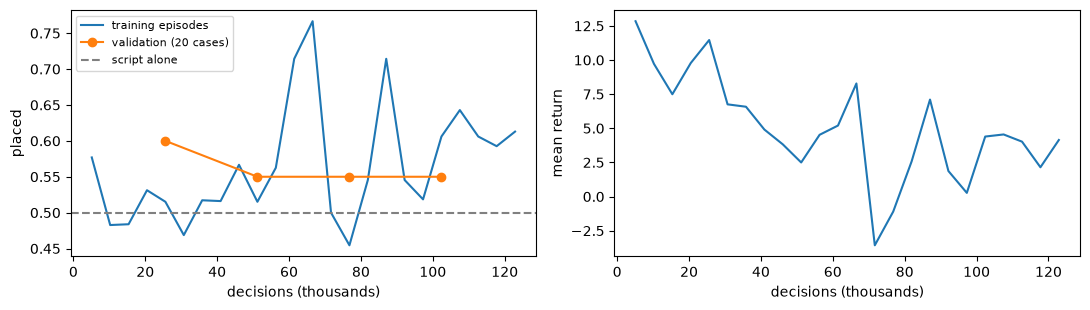

In [7]:
log = load("runs/insertion_mix/log.jsonl")
if log:
    x = [r["decisions"] / 1000 for r in log]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
    ax[0].plot(x, [r["train_success"] for r in log], label="training episodes")
    v = [(r["decisions"] / 1000, r["val_success"]) for r in log if "val_success" in r]
    base = load("runs/insertion_mix/baseline.json")
    if v:
        ax[0].plot(*zip(*v), "o-", label="validation (20 cases)")
    if base:
        ax[0].axhline(np.mean([b["outcome"] == "success" for b in base]), color="grey", ls="--", label="script alone")
    ax[0].set_xlabel("decisions (thousands)"); ax[0].set_ylabel("placed"); ax[0].legend(fontsize=8)
    ax[1].plot(x, [r["train_return"] for r in log]); ax[1].set_xlabel("decisions (thousands)"); ax[1].set_ylabel("mean return")
    plt.tight_layout()

In [8]:
key = lambda r: (r["scenario"], r["geometry_seed"], r["variant"])
base = load("runs/insertion_mix/baseline.json")
if base:
    B = {key(r): r for r in base}
    ok = lambda r: r["outcome"] == "success"
    print(f"script alone: {rate(sum(map(ok, B.values())), len(B))}")
    for p in sorted((ROOT / "runs/insertion_mix").glob("val_*.json")):
        V = {key(r): r for r in json.load(open(p))}
        n, rescued, lost, pv = paired(V, B, ok)
        print(f"{p.stem}: residual {rate(sum(map(ok, V.values())), len(V))}; rescued {len(rescued)}, "
              f"lost {len(lost)}, exact p = {pv:.2g}")
test = load("results/residual_test.json")
if test:
    print(f"\nHELD-OUT TEST: script {test['script']['success']:.2f}, residual {test['policy']['success']:.2f}, "
          f"recovered {test['recovered']}, lost {test['lost']}")

script alone: 10/20 = 50% [30, 70]
val_00005: residual 12/20 = 60% [39, 78]; rescued 2, lost 0, exact p = 0.5
val_00010: residual 11/20 = 55% [34, 74]; rescued 2, lost 1, exact p = 1
val_00015: residual 11/20 = 55% [34, 74]; rescued 2, lost 1, exact p = 1
val_00020: residual 11/20 = 55% [34, 74]; rescued 2, lost 1, exact p = 1
(missing: results/residual_test.json)


## 6. Learned high-level policy against the rules

Seeds 0–24 of each scenario, `noisy-learned` perception, the same rows and noise for both. Paired.

In [9]:
R, Q = by_row(load("results/hl_eval_rules.jsonl")), by_row(load("results/hl_eval_q.jsonl"))
if R and Q:
    for s in SCEN:
        ks = [k for k in R if k[0] == s and k in Q]
        print(f"{s:8} rules {rate(sum(bool(R[k].get('success')) for k in ks), len(ks)):24} "
              f"policy {rate(sum(bool(Q[k].get('success')) for k in ks), len(ks))}")
    n, only_r, only_q, p = paired(R, Q)
    print(f"\nall {n} rows: only the rules placed {len(only_r)}, only the policy {len(only_q)}, exact p = {p:.2g}")
    print(f"steps a row: rules {np.mean([len(r['steps']) for r in R.values()]):.2f}, "
          f"policy {np.mean([len(r['steps']) for r in Q.values()]):.2f}")

clear    rules 24/25 = 96% [80, 99]     policy 24/25 = 96% [80, 99]
tight    rules 18/25 = 72% [52, 86]     policy 18/25 = 72% [52, 86]
leaning  rules 21/25 = 84% [65, 94]     policy 21/25 = 84% [65, 94]
packed   rules 13/25 = 52% [33, 70]     policy 13/25 = 52% [33, 70]

all 100 rows: only the rules placed 2, only the policy 2, exact p = 1
steps a row: rules 2.25, policy 2.36


## 7. The cart demo, rules against the policy

`results/hl_cart.txt`: the full pipeline (tray, labels, wrist camera with simulation masks, fiducials),
seeds 0–2 of each scenario. Only 12 scenes: a demonstration, not a statistical test.

In [10]:
p = ROOT / "results/hl_cart.txt"
cart = collections.defaultdict(dict)
for line in (open(p) if p.exists() else []):
    head, _, tail = line.partition("|")
    s, seed, mode = head.split()
    cart[(s, int(seed))][mode] = tail.strip().startswith("SUCCESS")
for mode in ("rules", "policy"):
    print(mode, rate(sum(v.get(mode, False) for v in cart.values()), len(cart)),
          " failed:", [f"{k[0]} {k[1]}" for k, v in sorted(cart.items()) if not v.get(mode)])

rules 10/12 = 83% [55, 95]  failed: ['packed 0', 'packed 1']
policy 10/12 = 83% [55, 95]  failed: ['packed 0', 'packed 1']


## 8. One table for the report

Everything above in one place. `*` marks results that are incomplete or not held out.

In [11]:
def pct(D, s=None, ok=lambda r: bool(r.get("success"))):
    rs = [r for k, r in D.items() if s is None or k[0] == s]
    return f"{100*sum(map(ok, rs))/len(rs):.0f}% (n={len(rs)})" if rs else "-"
part = lambda D: "* (packed incomplete: overall rate too high)" if len(D) < 200 else ""
rows = [("Controller, truth, real books", pct(cols["truth"]) + part(cols["truth"])),
        ("Controller, camera + learned masks, real books", pct(cols["camera"]) + part(cols["camera"])),
        ("Camera with fiducials (box books, clear+tight)", pct(fid["fid_camera"])),
        ("Camera without fiducials (same rows)", pct(fid["fid_camera_nofid"])),
        ("High-level: rules (noisy-learned)", pct(R)), ("High-level: learned policy", pct(Q))]
if base:
    rows += [("Residual val: script alone (20 hard cases)*", pct(B, ok=lambda r: r["outcome"] == "success"))]
    V5 = {key(r): r for r in json.load(open(ROOT / "runs/insertion_mix/val_00005.json"))}
    rows += [("Residual val: best.pt (picked on these cases)*", pct(V5, ok=lambda r: r["outcome"] == "success"))]
w = max(len(a) for a, _ in rows)
for a, b in rows:
    print(f"{a:{w}}  {b}")

Controller, truth, real books                   97% (n=176)* (packed incomplete: overall rate too high)
Controller, camera + learned masks, real books  87% (n=152)* (packed incomplete: overall rate too high)
Camera with fiducials (box books, clear+tight)  92% (n=200)
Camera without fiducials (same rows)            81% (n=200)
High-level: rules (noisy-learned)               76% (n=100)
High-level: learned policy                      76% (n=100)
Residual val: script alone (20 hard cases)*     50% (n=20)
Residual val: best.pt (picked on these cases)*  60% (n=20)


## 9. How each file was made

```bash
# 2. controller, real books (results/slide_check/run.sh and camera_mps.sh; rows already done are skipped)
common="--catalogue --book-pages 4 --book-meshes --scenarios clear tight leaning packed --seeds 0:50"
uv run python -m bila.control.eval_reshelve run --perception truth $common --out results/slide_check/truth.jsonl
uv run --group rl python -m bila.control.eval_reshelve run --perception camera \
    --segmenter bila_weights/segmenter/segmenter.pt $common --out results/slide_check/camera.jsonl
# 3. fiducials: --perception truth / camera / camera --no-fiducials --scenarios clear tight --seeds 0:100
# 4-5. residual: results/find_hard.sh, hard_cases mix, results/train_mix.sh; the held-out test:
bash results/after_eval.sh     # labels the 30000+ pools, builds _test50
uv run --group rl python -m bila.rl.hard_cases test --run runs/insertion_mix --out results/residual_test.json
# 6. high-level: results/hl.sh, high_level fit, results/hl_eval.sh
# 7. cart: results/hl_cart.sh
```

**Still to run before the report's numbers are final:** the packed rows of section 2 (about 40 minutes)
and the residual's held-out test (section 5). This notebook picks both up when their files are complete.